# 2D Chebyshev interpolation

In higher dimensions the workflow is the same, with one extra convention: the
values must be sampled on the **tensor grid** of per-axis Chebyshev nodes,
built with `np.meshgrid(..., indexing='ij')` so that `vals[i, j]`
corresponds to `(x_i, y_j)`. A single 2D DCT then produces all coefficients
at once.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from chebyshevnd import ChebyshevInterpolant2D, chebyshev_nodes

In [2]:
f = lambda x, y: np.exp(-(x**2 + y**2) / 2) * np.cos(2 * x + y)
ax_, bx_ = -2.0, 2.0
ay_, by_ = -2.0, 2.0
Nx, Ny = 40, 40

x_nodes = chebyshev_nodes(Nx, ax_, bx_)
y_nodes = chebyshev_nodes(Ny, ay_, by_)
X, Y = np.meshgrid(x_nodes, y_nodes, indexing="ij")

interp = ChebyshevInterpolant2D(f(X, Y), ax_, bx_, ay_, by_)

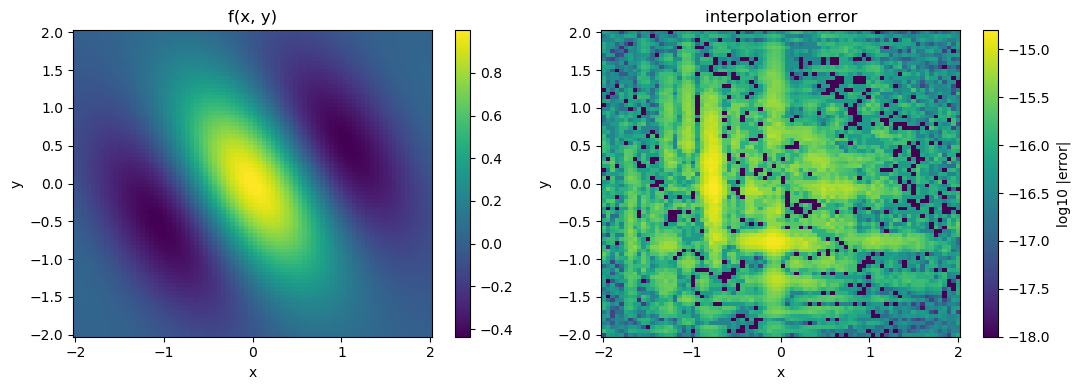

max error on the test grid: 1.582e-15
estimated absolute error:   7.105e-16


In [3]:
# Evaluate on an equally spaced test grid and compare with the true function
xt = np.linspace(ax_, bx_, 80)
yt = np.linspace(ay_, by_, 80)
Z_true = f(*np.meshgrid(xt, yt, indexing="ij"))
Z_interp = np.array([[interp.evaluate(x, y) for y in yt] for x in xt])
err = np.abs(Z_interp - Z_true)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
im1 = ax1.pcolormesh(xt, yt, Z_true.T, shading="auto")
fig.colorbar(im1, ax=ax1)
ax1.set_title("f(x, y)")
im2 = ax2.pcolormesh(xt, yt, np.log10(err.T + 1e-18), shading="auto")
fig.colorbar(im2, ax=ax2, label="log10 |error|")
ax2.set_title("interpolation error")
for axis in (ax1, ax2):
    axis.set_xlabel("x")
    axis.set_ylabel("y")
plt.tight_layout()
plt.show()

print(f"max error on the test grid: {err.max():.3e}")
print(f"estimated absolute error:   {interp.absolute_error():.3e}")

## Coefficient structure

The coefficient matrix decays away from the (0, 0) corner; how fast it decays
along each axis is what the truncation machinery exploits.

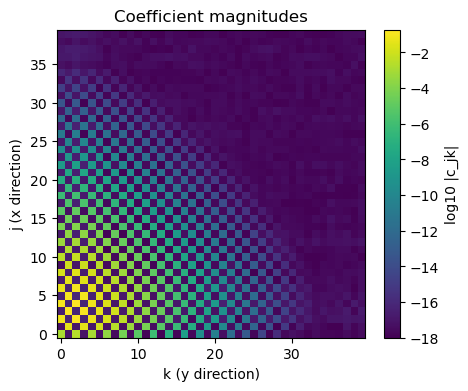

In [4]:
plt.figure(figsize=(5, 4))
plt.imshow(np.log10(np.abs(interp.get_coefficients()) + 1e-18), origin="lower")
plt.colorbar(label="log10 |c_jk|")
plt.xlabel("k (y direction)")
plt.ylabel("j (x direction)")
plt.title("Coefficient magnitudes")
plt.show()

## Truncating with `optimize`

`optimize(rel_tol)` computes per-row truncation counts, so rows whose
coefficients decay quickly use shorter Clenshaw recursions. `effective_grid()`
reports the reduced sizes.

In [5]:
print(f"full grid:      {[Nx, Ny]}")
interp.optimize(rel_tol=1e-10)
print(f"effective grid: {interp.effective_grid()}")

Z_opt = np.array([[interp.evaluate(x, y) for y in yt] for x in xt])
print(f"max error after truncation: {np.max(np.abs(Z_opt - Z_true)):.3e}")

full grid:      [40, 40]
effective grid: [31, 29]
max error after truncation: 8.216e-14
